<a href="https://colab.research.google.com/github/SlepenkovaDaria/Statistical_Experiments/blob/main/A_B_%D1%82%D0%B5%D1%81%D1%82.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest
from google.colab import files

# A/B-тест новой формы оплаты ЖКХ

**Цель:** оценить, повышает ли новая форма с упрощённым заполнением реквизитов
долю успешных оплат ЖКХ.

**Период теста:** 1–30 апреля 2024 года.

**Ключевая метрика:** конверсия из открытия формы (`Step 1`)
в успешную оплату (`Step 4`).

**Гипотеза:** новая форма (группа B) увеличивает конверсию в успешную оплату.

#  Загрузка данных

In [3]:
uploaded = files.upload()

Saving dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx to dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx


In [4]:
filename = next(iter(uploaded))
print(filename)

excel_file = pd.ExcelFile(filename)
excel_file.sheet_names

dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx


['Пользователи', 'Платежи']

In [5]:
users = pd.read_excel(filename, sheet_name = 'Пользователи')
payments = pd.read_excel(filename, sheet_name = 'Платежи')

print('Размер таблицы users:', users.shape)
print('Размер таблицы payments:', payments.shape)

display(users.head())
display(payments.head())


Размер таблицы users: (1504, 5)
Размер таблицы payments: (2661, 7)


,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,1001.0,A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,1002.0,A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,1003.0,A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,1004.0,A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,1004.0,A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


# Проверка и очистка данных

**Таблица Users**

In [6]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      1504 non-null   int64 
 1   group        1503 non-null   object
 2   age          1504 non-null   int64 
 3   city         1503 non-null   object
 4   device_type  1504 non-null   object
dtypes: int64(2), object(3)
memory usage: 58.9+ KB


In [7]:
users.describe(include = 'all')

,user_id,group,age,city,device_type
count,1504.000000,1503,1504.000000,1503,1504
unique,NaN,2,NaN,3,2
top,NaN,A,NaN,Москва,android
freq,NaN,752,NaN,595,777
mean,1769.787234,NaN,32.745346,NaN,NaN
std,571.592080,NaN,8.410915,NaN,NaN
min,1001.000000,NaN,-5.000000,NaN,NaN
25%,1376.750000,NaN,27.000000,NaN,NaN
50%,1752.500000,NaN,33.000000,NaN,NaN
75%,2128.250000,NaN,38.000000,NaN,NaN


In [8]:
pd.DataFrame({'missing': users.isna().sum(),'missing_pct': users.isna().mean() * 100})

,missing,missing_pct
user_id,0,0.000000
group,1,0.066489
age,0,0.000000
city,1,0.066489
device_type,0,0.000000


In [9]:
print('Количество строк:', len(users))
print('Уникальных user_id:', users['user_id'].nunique())
print('Дубликатов user_id:', users['user_id'].duplicated().sum())

Количество строк: 1504
Уникальных user_id: 1504
Дубликатов user_id: 0


In [10]:
users['group'].value_counts(dropna = False)

,count
group,
A,752
B,751
NaN,1


In [11]:
users['city'].value_counts(dropna = False)

,count
city,
Москва,595
Регион,514
СПб,394
NaN,1


In [12]:
users['device_type'].value_counts(dropna = False)

,count
device_type,
android,777
ios,727


In [13]:
problem_users = users[users['group'].isna() | users['city'].isna() | (users['age'] < 0) | (users['age'] > 100)]
problem_users

,user_id,group,age,city,device_type
1500,9001,NaN,25,Москва,ios
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios
1503,9004,A,30,NaN,android


In [14]:
payments[payments['user_id'].isin([9001, 9002, 9003, 9004])]

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2657,7658,9004.0,A,2024-04-05 16:14:00,2024-04-05 16:15:00,2024-04-05 16:18:00,2024-04-05 16:23:00



### Вывод
В таблице 1504 уникальных пользователя, дубликаты `user_id` отсутствуют.Группы A и B практически равны по размеру.

Были обнаружены четыре аномальные записи пользователей. Два некорректных значения возраста (-5 и 150) заменим на пропуски, так как остальные данные этих пользователей могут оставаться валидными. Для пользователя с отсутствующим городом значение заменим на `Unknown`. Пользователя с отсутствующей экспериментальной группой сохраним без искусственного восстановления группы, поскольку в таблице платежей записи этого пользователя отсутствуют.

In [16]:
users_clean = users.copy()
users_clean.loc[(users_clean['age'] < 0) | (users_clean['age'] > 100), 'age'] = np.nan
users_clean['city'] = users_clean['city'].fillna('Unknown')

**Таблица Payments**

In [17]:
payments.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2661 entries, 0 to 2660
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2661 non-null   int64         
 1   user_id          2660 non-null   float64       
 2   group            2661 non-null   object        
 3   step1_opened     2661 non-null   datetime64[ns]
 4   step2_entered    2256 non-null   datetime64[ns]
 5   step3_confirmed  1719 non-null   datetime64[ns]
 6   step4_success    1522 non-null   datetime64[ns]
dtypes: datetime64[ns](4), float64(1), int64(1), object(1)
memory usage: 145.7+ KB


In [18]:
payments.describe(include = 'all')

,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
count,2661.000000,2660.000000,2661,2661,2256,1719,1522
unique,NaN,NaN,2,NaN,NaN,NaN,NaN
top,NaN,NaN,B,NaN,NaN,NaN,NaN
freq,NaN,NaN,1352,NaN,NaN,NaN,NaN
mean,6433.978579,1760.884211,NaN,2024-04-15 17:56:46.854565888,2024-04-15 14:21:25.904255488,2024-04-15 13:37:05.375218176,2024-04-15 12:22:53.534822656
min,5001.000000,1001.000000,NaN,2024-04-01 00:19:00,2024-04-01 00:23:00,2024-04-01 00:29:00,2024-04-01 00:33:00
25%,5666.000000,1388.000000,NaN,2024-04-08 01:30:00,2024-04-07 22:25:45,2024-04-07 19:01:00,2024-04-07 22:22:00
50%,6331.000000,1762.500000,NaN,2024-04-15 15:30:00,2024-04-15 05:12:30,2024-04-15 05:23:00,2024-04-14 23:01:00
75%,6996.000000,2135.250000,NaN,2024-04-23 13:25:00,2024-04-23 12:43:00,2024-04-23 14:28:00,2024-04-23 11:49:30
max,99003.000000,9004.000000,NaN,2024-04-30 23:17:00,2024-04-30 23:20:00,2024-04-30 23:25:00,2024-04-30 23:30:00


In [19]:
pd.DataFrame({'missing': payments.isna().sum(),'missing_pct': payments.isna().mean() * 100})

,missing,missing_pct
payment_id,0,0.000000
user_id,1,0.037580
group,0,0.000000
step1_opened,0,0.000000
step2_entered,405,15.219842
step3_confirmed,942,35.400225
step4_success,1139,42.803457


In [24]:
print('Количество строк:', len(payments))
print('Уникальных payment_id:', payments['payment_id'].nunique())
print('Дубликатов payment_id:', payments['payment_id'].duplicated().sum())
print('Уникальных user_id:', payments['user_id'].nunique())
print('Пропущенных user_id:', payments['user_id'].isna().sum())

Количество строк: 2661
Уникальных payment_id: 2661
Дубликатов payment_id: 0
Уникальных user_id: 1501
Пропущенных user_id: 1


In [25]:
payments['group'].value_counts(dropna = False)

,count
group,
B,1352
A,1309


In [26]:
payments.groupby('user_id')['group'].nunique().value_counts()

,count
group,
1,1500
2,1


In [27]:
payments['user_id'].value_counts().describe()

,count
count,1501.000000
mean,1.772152
std,0.901878
min,1.000000
25%,1.000000
50%,2.000000
75%,2.000000
max,4.000000


In [28]:
payments_clean = payments.copy()
payments_clean = payments_clean[payments_clean['user_id'].notna()].copy()
payments_clean['user_id'] = payments_clean['user_id'].astype(int)
payments_clean = payments_clean.rename(columns = {'group': 'group_raw'})
payments_clean = payments_clean.merge(
    users_clean[['user_id', 'group']],
    on = 'user_id',
    how = 'left',
    validate = 'many_to_one'
)

In [29]:
payments_clean[payments_clean['group_raw'] != payments_clean['group']][['payment_id', 'user_id', 'group_raw', 'group']]

,payment_id,user_id,group_raw,group
2659,99002,1010,B,A


In [30]:
payments_clean = payments_clean.drop(columns = 'group_raw')

### Вывод

В таблице содержится 2661 платежная попытка. Дубликаты `payment_id`
и полные дубликаты платежных записей отсутствуют.

Обнаружены две проблемы качества данных:

- одна платежная попытка не содержит `user_id` и была исключена, потому что
  её невозможно связать с участником A/B-теста;
- для пользователя 1010 одна из попыток была ошибочно отнесена к группе B,
  в то время как пользователь закреплён за группой A. Экспериментальная группа
  была восстановлена из таблицы пользователей.

Остальные подозрительные записи сохранены, поскольку оснований считать их
невалидными не обнаружено.


# Корректность воронки

In [31]:
bad_step2 = payments_clean[payments_clean['step2_entered'].notna() & payments_clean['step1_opened'].isna()]
bad_step3 = payments_clean[payments_clean['step3_confirmed'].notna() & payments_clean['step2_entered'].isna()]
bad_step4 = payments_clean[payments_clean['step4_success'].notna() & payments_clean['step3_confirmed'].isna()]

print('Step2 есть, Step1 нет:', len(bad_step2))
print('Step3 есть, Step2 нет:', len(bad_step3))
print('Step4 есть, Step3 нет:', len(bad_step4))

Step2 есть, Step1 нет: 0
Step3 есть, Step2 нет: 0
Step4 есть, Step3 нет: 0


In [32]:
bad_12 = payments_clean[payments_clean['step2_entered'].notna() & (payments_clean['step2_entered'] < payments_clean['step1_opened'])]
bad_23 = payments_clean[payments_clean['step3_confirmed'].notna() & (payments_clean['step3_confirmed'] < payments_clean['step2_entered'])]
bad_34 = payments_clean[payments_clean['step4_success'].notna() & (payments_clean['step4_success'] < payments_clean['step3_confirmed'])]

print('Step2 раньше Step1:', len(bad_12))
print('Step3 раньше Step2:', len(bad_23))
print('Step4 раньше Step3:', len(bad_34))

Step2 раньше Step1: 0
Step3 раньше Step2: 0
Step4 раньше Step3: 0


In [33]:
print(payments_clean['step1_opened'].min(), payments_clean['step1_opened'].max())

2024-04-01 00:19:00 2024-04-30 23:17:00


Все проверки корректности воронки прошли идеально - нет пропущенных промежуточных шагов, нет нарушений временного порядка, а все открытия формы лежат внутри периода теста 1-30 апреля.

# Строим воронку A/B

In [34]:
funnel = (payments_clean.groupby('group').agg(
        step1 = ('step1_opened', 'count'),
        step2 = ('step2_entered', 'count'),
        step3 = ('step3_confirmed', 'count'),
        step4 = ('step4_success', 'count')
    )
)
funnel['cr_1_2'] = funnel['step2'] / funnel['step1']
funnel['cr_2_3'] = funnel['step3'] / funnel['step2']
funnel['cr_3_4'] = funnel['step4'] / funnel['step3']
funnel['cr_1_4'] = funnel['step4'] / funnel['step1']

funnel_pct = funnel.copy()
for col in ['cr_1_2', 'cr_2_3', 'cr_3_4', 'cr_1_4']:
    funnel_pct[col] = (funnel_pct[col] * 100).round(2)

funnel_pct


,step1,step2,step3,step4,cr_1_2,cr_2_3,cr_3_4,cr_1_4
group,,,,,,,,
A,1309,1062,759,652,81.13,71.47,85.90,49.81
B,1351,1194,960,870,88.38,80.40,90.62,64.40


In [35]:
conversion_cols = ['cr_1_2', 'cr_2_3', 'cr_3_4', 'cr_1_4']

effect = pd.DataFrame({'A': funnel.loc['A', conversion_cols] * 100, 'B': funnel.loc['B', conversion_cols] * 100})

effect['diff_pp'] = effect['B'] - effect['A']
effect['relative_uplift_pct'] = ((effect['B'] / effect['A'] - 1) * 100)
effect.round(2)

,A,B,diff_pp,relative_uplift_pct
cr_1_2,81.13,88.38,7.25,8.93
cr_2_3,71.47,80.40,8.93,12.50
cr_3_4,85.90,90.62,4.72,5.50
cr_1_4,49.81,64.40,14.59,29.29


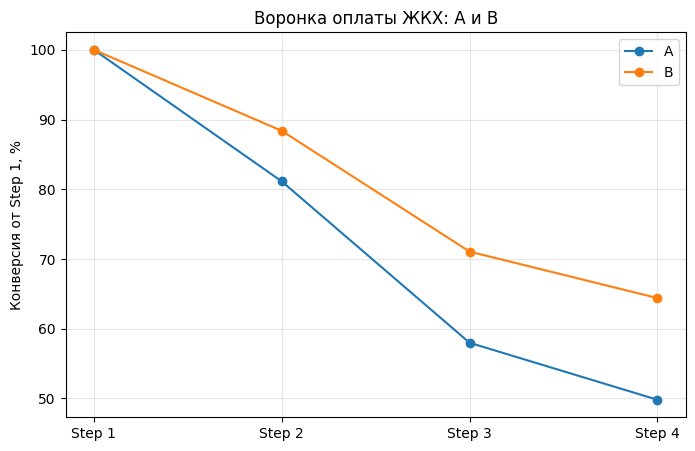

In [36]:
steps = ['Step 1', 'Step 2', 'Step 3', 'Step 4']
conv_A = [
    100,
    funnel.loc['A', 'step2'] / funnel.loc['A', 'step1'] * 100,
    funnel.loc['A', 'step3'] / funnel.loc['A', 'step1'] * 100,
    funnel.loc['A', 'step4'] / funnel.loc['A', 'step1'] * 100
]
conv_B = [
    100,
    funnel.loc['B', 'step2'] / funnel.loc['B', 'step1'] * 100,
    funnel.loc['B', 'step3'] / funnel.loc['B', 'step1'] * 100,
    funnel.loc['B', 'step4'] / funnel.loc['B', 'step1'] * 100
]
plt.figure(figsize = (8, 5))
plt.plot(steps, conv_A, marker = 'o', label = 'A')
plt.plot(steps, conv_B, marker = 'o', label = 'B')

plt.ylabel('Конверсия от Step 1, %')
plt.title('Воронка оплаты ЖКХ: A и B')
plt.legend()
plt.grid(alpha = 0.3)

plt.show()

Группа B показывает более высокую конверсию на всех этапах воронки.

# User-level таблица

In [37]:
user_results = (payments_clean.groupby(['user_id', 'group']).agg(
        attempts = ('payment_id', 'count'),
        successes = ('step4_success', lambda x: x.notna().sum())
    ).reset_index())

user_results['success_any'] = (user_results['successes'] > 0).astype(int)
user_results.head()

,user_id,group,attempts,successes,success_any
0,1001,A,1,0,0
1,1002,A,1,0,0
2,1003,A,1,0,0
3,1004,A,3,2,1
4,1005,A,2,1,1


In [38]:
user_summary = (user_results.groupby('group')
    .agg(users = ('user_id', 'count'), successful_users = ('success_any', 'sum'), conversion = ('success_any', 'mean')))
user_summary['conversion_pct'] = (user_summary['conversion'] * 100).round(2)
user_summary

,users,successful_users,conversion,conversion_pct
group,,,,
A,751,494,0.65779,65.78
B,750,603,0.80400,80.40


Сгруппировали данные на уровне пользователей и для каждого клиента определили наличие хотя бы одной успешной оплаты. В результате user-level конверсия составила 65.78% в группе A и 80.40% в группе B.

# Формулировка гипотезы и реализация критерия

$$H_0: p_B \leq p_A$$
$$H_1: p_B > p_A$$

In [39]:
success_A = user_results.loc[user_results['group'] == 'A','success_any'].sum()
success_B = user_results.loc[user_results['group'] == 'B','success_any'].sum()

n_A = (user_results['group'] == 'A').sum()
n_B = (user_results['group'] == 'B').sum()

count = np.array([success_B, success_A])
nobs = np.array([n_B, n_A])

z_stat, p_value = proportions_ztest(count = count, nobs = nobs, alternative = 'larger')

print(f'z-statistic: {z_stat:.3f}')
print(f'p-value: {p_value:.2e}')

z-statistic: 6.386
p-value: 8.52e-11


In [40]:
p_A = success_A / n_A
p_B = success_B / n_B

diff = p_B - p_A

se = np.sqrt(p_A * (1 - p_A) / n_A + p_B * (1 - p_B) / n_B)
z_crit = 1.96
ci_low = diff - z_crit * se
ci_high = diff + z_crit * se

print(f'Разница конверсий B - A: {diff * 100:.2f} п.п.')
print(f'95% ДИ: [{ci_low * 100:.2f}; {ci_high * 100:.2f}] п.п.')

Разница конверсий B - A: 14.62 п.п.
95% ДИ: [10.20; 19.05] п.п.


B повышает user-level конверсию на 14.62 п.п.; 95% ДИ [10.20; 19.05] п.п., p-value ≈ $10^{-10}$. Эффект и статистически значимый, и практически большой.

# Проверка баланса групп и сегментный анализ

In [41]:
analysis_users = user_results.merge(users_clean[['user_id', 'age', 'city', 'device_type']],
    on = 'user_id',
    how = 'left',
    validate = 'one_to_one')

In [42]:
analysis_users.groupby('group')['age'].agg(['count', 'mean', 'median', 'std']).round(2)

,count,mean,median,std
group,,,,
A,751,32.74,32.0,7.82
B,750,32.65,33.0,7.78


In [43]:
pd.crosstab(analysis_users['group'], analysis_users['city'], normalize = 'index').round(3)

city,Unknown,Москва,Регион,СПб
group,,,,
A,0.001,0.383,0.357,0.258
B,0.000,0.408,0.327,0.265


In [44]:
pd.crosstab(analysis_users['group'], analysis_users['device_type'], normalize = 'index').round(3)

device_type,android,ios
group,,
A,0.542,0.458
B,0.492,0.508


Группы сопоставимы по возрасту и географии; по типу устройства наблюдается небольшой дисбаланс, не меняющий общий вывод теста.

# Рекомендации продуктовой команде

Запускать новую форму оплаты ЖКХ на всех пользователей. В группе B итоговая конверсия по платежным попыткам выросла с 49.81% до 64.40% (+14.59 п.п.), а user-level конверсия — с 65.78% до 80.40% (+14.62 п.п.). Эффект статистически значим (\(p<0.001\)), 95% ДИ для прироста user-level конверсии составляет [10.20; 19.05] п.п. Рост наблюдается уже на переходе Step 1 → Step 2, что согласуется с механикой новой формы с упрощённым вводом реквизитов.